In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from time import perf_counter

from sklearn.datasets import fetch_california_housing

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate,
    RandomizedSearchCV
)

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
housing = fetch_california_housing(as_frame = True)

X = housing.data
y= housing.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 42)



In [3]:
baseline = DummyRegressor(strategy = "mean")
modelos = {
    "Baseline": DummyRegressor(strategy = "mean"),
    "Linear Regression": LinearRegression(),
    "Desicion Tree": DecisionTreeRegressor(random_state = 42),
    "Random Forest": RandomForestRegressor(n_estimators= 20, random_state= 42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, learning_rate = 0.05, max_depth = 2, random_state = 42)    
}


In [4]:
cv = KFold(n_splits=5, random_state=42, shuffle=True)


In [5]:
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

In [6]:
resultados = []

for nombre, modelo in modelos.items():

    cv_result = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    resultados.append({
        "Modelo": nombre,

        "MAE_CV":
            -cv_result["test_MAE"].mean(),

        "MAE_SD":
            cv_result["test_MAE"].std(),

        "RMSE_CV":
            -cv_result["test_RMSE"].mean(),

        "RMSE_SD":
            cv_result["test_RMSE"].std(),

        "R2_CV":
            cv_result["test_R2"].mean(),

        "R2_SD":
            cv_result["test_R2"].std(),

        "Tiempo":
            cv_result["fit_time"].mean()
    })


In [7]:
df_resultados = pd.DataFrame(resultados)
df_resultados


,Modelo,MAE_CV,MAE_SD,RMSE_CV,RMSE_SD,R2_CV,R2_SD,Tiempo
0,Baseline,0.913915,0.010082,1.156172,0.012163,-0.000215,0.000213,0.001607
1,Linear Regression,0.529061,0.009383,0.720510,0.013895,0.611457,0.012359,0.201768
2,Desicion Tree,0.473804,0.016440,0.733320,0.023568,0.597252,0.023962,0.177865
3,Random Forest,0.344822,0.004916,0.525778,0.010981,0.793144,0.005533,0.497072
4,Gradient Boosting,0.405271,0.008466,0.572787,0.014558,0.754431,0.010070,4.864420


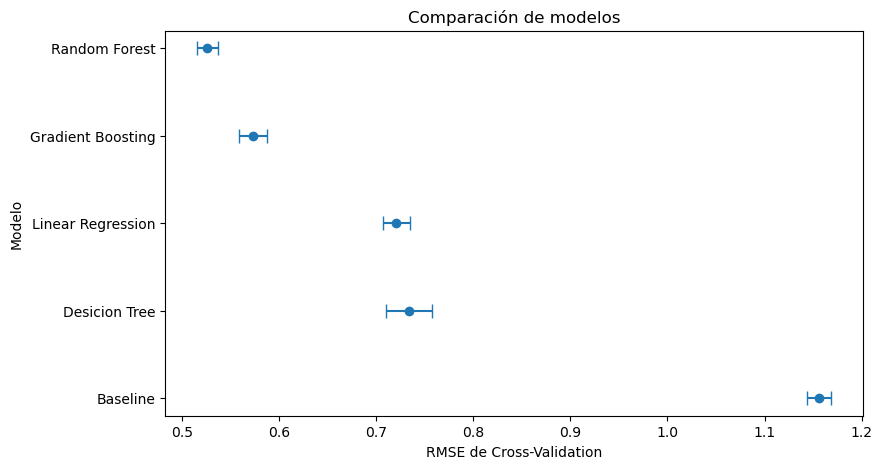

In [8]:
df_plot = df_resultados.sort_values(
    "RMSE_CV",
    ascending=False
)

plt.figure(figsize=(9, 5))

plt.errorbar(
    df_plot["RMSE_CV"],
    df_plot["Modelo"],
    xerr=df_plot["RMSE_SD"],
    fmt="o",
    capsize=5
)

plt.xlabel("RMSE de Cross-Validation")
plt.ylabel("Modelo")
plt.title("Comparación de modelos")
plt.show()

In [9]:
modelos_comparar = {
    "Random Forest": RandomForestRegressor(n_estimators= 20, random_state= 42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, learning_rate = 0.05, max_depth = 2, random_state = 42)    
}


resultados = []

for nombre, modelo in modelos_comparar.items():

    cv_result = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    resultados.append({
            "Modelo": nombre,
    
            "RMSE_CV":
                -cv_result["test_RMSE"],
    
            "RMSE_SD":
                cv_result["test_RMSE"],
    
        })

resultados

[{'Modelo': 'Random Forest',
  'RMSE_CV': array([0.53886326, 0.51311614, 0.52476159, 0.53769523, 0.51445245]),
  'RMSE_SD': array([-0.53886326, -0.51311614, -0.52476159, -0.53769523, -0.51445245])},
 {'Modelo': 'Gradient Boosting',
  'RMSE_CV': array([0.58945794, 0.56738891, 0.5513569 , 0.58885872, 0.56687094]),
  'RMSE_SD': array([-0.58945794, -0.56738891, -0.5513569 , -0.58885872, -0.56687094])}]

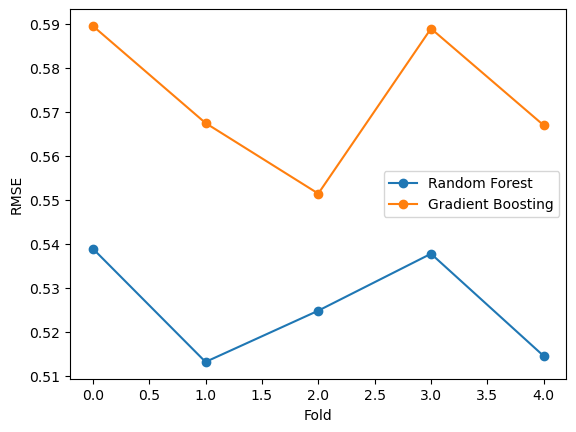

In [10]:
plt.figure()
plt.plot(resultados[0]["RMSE_CV"], marker = "o", label = resultados[0]["Modelo"])
plt.plot(resultados[1]["RMSE_CV"], marker = "o", label =resultados[1]["Modelo"] )
plt.legend()
plt.xlabel("Fold")
plt.ylabel("RMSE")
plt.show()

In [11]:
param_rf = {
    "n_estimators": [100,200,400],
    "max_depth": [None, 10,20,30],
    "max_features": [0.5,0.75,1.0],
    "min_samples_leaf": [1,2,4]
}

search_rf = RandomizedSearchCV(
    estimator = RandomForestRegressor(
        random_state=42,
        n_jobs=-1,
        
    ),
    param_distributions= param_rf,
    n_iter = 12,
    scoring = "neg_root_mean_squared_error",
    cv = cv,
    random_state = 42,
    n_jobs = -1
)

In [12]:
inicio = perf_counter()
search_rf.fit(X_train,y_train)
tiempo_rf = perf_counter() - inicio


In [13]:
search_rf.best_params_
-search_rf.best_score_

np.float64(0.49841289414696427)

In [14]:
param_gb = {
    "n_estimators": [100,200,300,500],
    "learning_rate": [0.01,0.03,0.05,0.1],
    "max_depth": [1,2,3,4],
    "subsample": [0.7, 0.8,0.9,1.0]
}

In [15]:
search_gb = RandomizedSearchCV(
    estimator = GradientBoostingRegressor(
        random_state = 42
    ),
    param_distributions = param_gb,
    n_iter = 12,
    scoring = "neg_root_mean_squared_error",
    cv = cv,
    random_state = 42,
    n_jobs = -1
)

In [16]:
inicio = perf_counter()
search_gb.fit(X_train,y_train)
tiempo_gb = perf_counter()-inicio
tiempo_gb

88.42680096200002

In [17]:
modelo_rf_final = search_rf.best_estimator_
modelo_gb_final = search_gb.best_estimator_


In [18]:
pred_rf_test = modelo_rf_final.predict(X_test)
pred_gb_test = modelo_gb_final.predict(X_test)


In [19]:
def  metricas_de_regresión(y_real, y_pred):
    mae = mean_absolute_error(y_real,y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    r2 = r2_score(y_real, y_pred)
    return mae, rmse, r2

mae_rf, rmse_rf, r2_rf = metricas_de_regresión(y_test, pred_rf_test)
mae_gb, rmse_gb, r2_gb = metricas_de_regresión(y_test, pred_gb_test)

resultados_test = pd.DataFrame({
    "Modelo": [
        "Random Forest",
        "Gradient Boosting"
    ],

    "MAE_test": [
        mae_rf,
        mae_gb
    ],

    "RMSE_test": [
        rmse_rf,
        rmse_gb
    ],

    "R2_test": [
        r2_rf,
        r2_gb
    ]
})

resultados_test


,Modelo,MAE_test,RMSE_test,R2_test
0,Random Forest,0.321067,0.494598,0.813320
1,Gradient Boosting,0.331691,0.493242,0.814342


In [20]:
comparacion_final = pd.DataFrame({
    "Modelo": ["Random Forest","Gradient Boosting"],
    "RMSE_CV": [-search_rf.best_score_, -search_gb.best_score_],
    "RMSE_test": [rmse_rf,rmse_gb]
})
comparacion_final

,Modelo,RMSE_CV,RMSE_test
0,Random Forest,0.498413,0.494598
1,Gradient Boosting,0.492603,0.493242


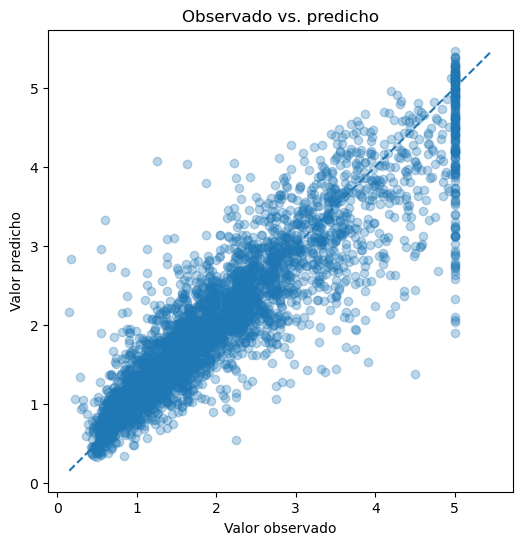

In [21]:
plt.figure(figsize = (6,6))
plt.scatter(y_test, pred_gb_test, alpha = 0.3)
limites = [min(y_test.min(), pred_gb_test.min()),
          max(y_test.max(), pred_gb_test.max())]
plt.plot(limites, limites, linestyle= "--")
plt.xlabel("Valor observado")
plt.ylabel("Valor predicho")

plt.title("Observado vs. predicho")
plt.show()

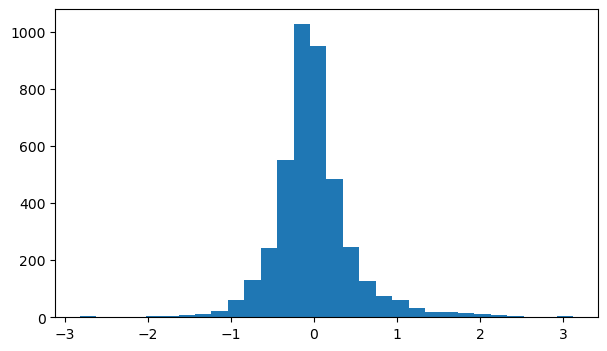

In [22]:
residuos = y_test - pred_gb_test
plt.figure(figsize=(7,4))
plt.hist(residuos, bins = 30)
plt.show()

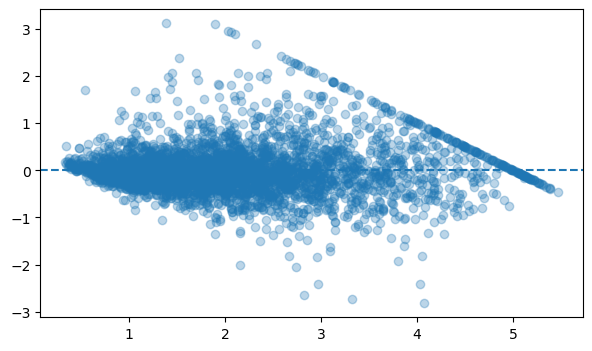

In [23]:
residuos = y_test - pred_gb_test
plt.figure(figsize=(7,4))
plt.scatter(pred_gb_test,residuos, alpha = 0.3)
plt.axhline(0, linestyle = "--")
plt.show()

In [24]:
diagnostico = X_test.copy()
diagnostico["y_real"] = y_test

diagnostico["y_pred"] = pred_gb_test
diagnostico["residuo"] = (diagnostico["y_real"]-diagnostico["y_pred"])
diagnostico["error_absoluto"] = (diagnostico["residuo"].abs())
diagnostico.sort_values("error_absoluto",ascending = False)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,y_real,y_pred,residuo,error_absoluto
19542,1.7679,39.0,5.000000,0.888889,22.0,2.444444,37.63,-120.92,4.50000,1.379973,3.120027,3.120027
10574,1.9659,6.0,4.795455,1.159091,125.0,2.840909,33.72,-117.70,5.00001,1.890466,3.109544,3.109544
12069,4.2386,6.0,7.723077,1.169231,228.0,3.507692,33.83,-117.55,5.00001,2.033595,2.966415,2.966415
12389,3.7727,24.0,10.953586,1.848101,473.0,1.995781,33.75,-116.43,5.00001,2.061585,2.938425,2.938425
459,1.1696,52.0,2.436000,0.944000,1349.0,5.396000,37.87,-122.25,5.00001,2.100709,2.899301,2.899301
...,...,...,...,...,...,...,...,...,...,...,...,...
11917,2.9583,37.0,5.200000,0.927869,675.0,2.213115,33.95,-117.41,1.32100,1.320447,0.000553,0.000553
4119,5.5524,52.0,6.129032,1.041935,1842.0,2.970968,34.14,-118.20,2.93900,2.938517,0.000483,0.000483
576,7.2634,12.0,7.133034,1.018934,5781.0,2.880419,37.77,-122.06,3.41600,3.415701,0.000299,0.000299
697,2.6464,37.0,3.954693,1.053398,1562.0,2.527508,37.69,-122.11,1.55200,1.551918,0.000082,0.000082


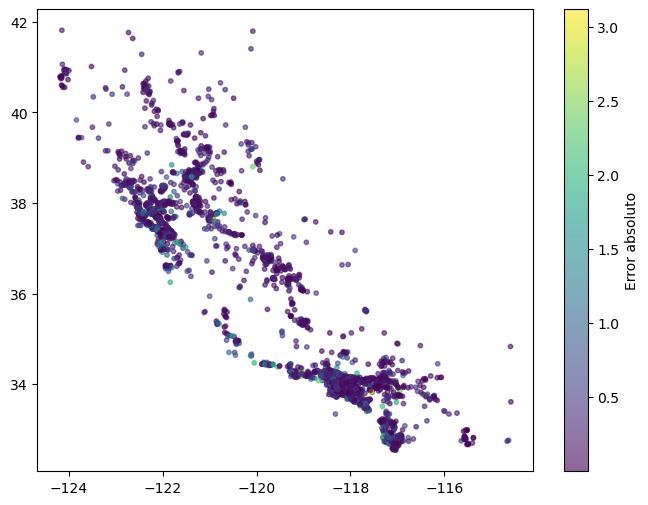

In [25]:
plt.figure(figsize = (8,6))
plt.scatter(diagnostico["Longitude"],diagnostico["Latitude"],c=diagnostico["error_absoluto"], s= 10, alpha = 0.6)
plt.colorbar(label = "Error absoluto")
plt.show()

# Ejercicio

## 1 
Ahora realizarás el mismo flujo utilizando XGBoost.

¿El desempeño sobre test fue consistente con el estimado mediante Cross-Validation?

Si, son parecidos

¿Qué información adicional obtuviste al observar los residuos que no era visible únicamente con RMSE?

que hay valores en los que los residuos no parecen ser aleatorios


In [26]:
from xgboost import XGBRegressor
xgb = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=1
)
param_xgb = {
    "n_estimators": [100, 200, 300, 500],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4, 5],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

res = RandomizedSearchCV(xgb,param_xgb,n_iter = 15, scoring = 'neg_root_mean_squared_error',    cv = cv,
    random_state = 42,
    n_jobs = -1)

In [27]:
res.fit(X_train,y_train)

RandomizedSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=XGBRegressor(base_score=None, booster=None,
                                          callbacks=None,
                                          colsample_bylevel=None,
                                          colsample_bynode=None,
                                          colsample_bytree=None, device=None,
                                          early_stopping_rounds=None,
                                          enable_categorical=True,
                                          eval_metric=None, feature_types=None,
                                          feature_weights=None, gamma=None,
                                          grow_policy=None...
                                          monotone_constraints=None,
                                          multi_strategy=None,
                                          n_estimators=None, n_jobs=1,
                                          num_parallel_tree=None, ...),
                   n_iter=15, n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.7, 0.8, 0.9,
                                                             1.0],
                                        'learning_rate': [0.01, 0.03, 0.05,
                                                          0.1],
                                        'max_depth': [2, 3, 4, 5],
                                        'n_estimators': [100, 200, 300, 500],
                                        'subsample': [0.7, 0.8, 0.9, 1.0]},
                   random_state=42, scoring='neg_root_mean_squared_error')

In [28]:
#Mejores parametros
print("Mejores  parametros: ",res.best_params_)
print("RMSE promedio: ", -res.best_score_)
#MAE, RMSE, R2 en el test
modelo_f = res.best_estimator_

y_pred = modelo_f.predict(X_test)
#Metricas
rmse = np.sqrt(mean_squared_error(y_test,y_pred))
mae = mean_absolute_error(y_test,y_pred)
r2 = r2_score(y_test,y_pred)

print("rmse: ",rmse)
print("mae: ", mae)
print("R2:", r2)

Mejores  parametros:  {'subsample': 0.7, 'n_estimators': 500, 'max_depth': 5, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
RMSE promedio:  0.46051936529435605
rmse:  0.45288404250883707
mae:  0.30114984454147803
R2: 0.8434809594829862


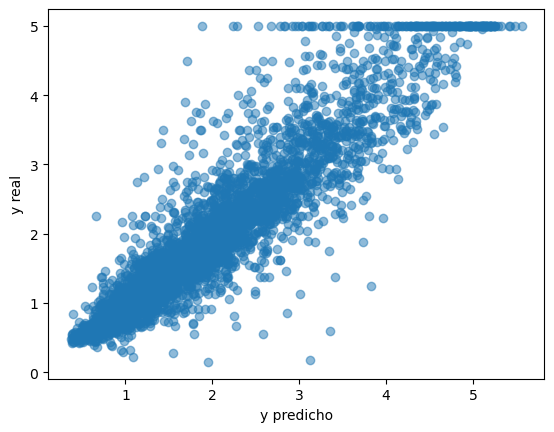

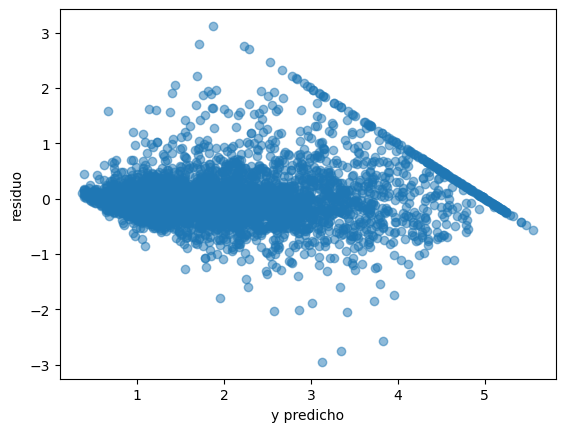

In [29]:
plt.figure()
plt.scatter(y_pred,y_test, alpha =0.5)
plt.xlabel("y predicho")
plt.ylabel("y real")
plt.show()

plt.figure()
plt.scatter(y_pred,y_test-y_pred, alpha =0.5)
plt.xlabel("y predicho")
plt.ylabel("residuo")
plt.show()

## 11.24 Reto adicional: clasificación
Hasta ahora toda nuestra práctica se ha desarrollado sobre un problema de regresión.

Sin embargo, el procedimiento general también puede utilizarse en clasificación.

scikit-learn contiene el conjunto Breast Cancer Wisconsin.

Puedes cargarlo mediante:

In [34]:
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier

cancer = load_breast_cancer(
    as_frame=True
)

X_cancer = cancer.data
y_cancer = cancer.target

from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits = 10, shuffle = True, random_state = 42)

X_train, X_test, y_train, y_test = train_test_split(X_cancer, y_cancer, test_size = 0.20, random_state = 42)

pipe = Pipeline([('scaler', StandardScaler()), ('log', LogisticRegression())])
pipe2 = Pipeline([('scaler', StandardScaler()), ('dum', DummyClassifier(strategy="most_frequent"))])


In [35]:


cross = cross_validate(pipe,X_train,y_train, cv = cv, scoring='roc_auc')
cross2 = cross_validate(pipe2,X_train,y_train, cv = cv, scoring='roc_auc')

In [36]:
df = pd.DataFrame(cross)
print("Modelo de regresión logistica: ",df["test_score"].mean())

df2 = pd.DataFrame(cross2)
print("Modelo de classificación dummy", df2["test_score"].mean())

Modelo de regresión logistica:  0.9948855404230658
Modelo de classificación dummy 0.5


qué modelo utilizarías como baseline;

RESPUESTA: La de clasificación dummy

qué estrategia de Cross-Validation utilizarías;

RESPUESTA: la de la validación cruzada estratificada

qué métricas reportarías;

RESPUESTA: la accuracy, precision, recall, F1, ROC-AUC, y ademas la matriz de confusión

qué modelos compararías;

RESPUESTA: La regresión logistica, y la dummy

qué información reservarías hasta la evaluación final.

RESPUESTA: el 20 porciento de los datos.